# 01 · Preprocessing — Caron 2020 Acute Lymphoblastic Leukemia (malignant compartment)

Caron *et al.* 2020 profiled **pediatric acute lymphoblastic leukemia** by 10x across **8 malignant
samples** spanning three genetically distinct subtypes — *ETV6-RUNX1* pre-B ALL, high-hyperdiploid
(HHD) pre-B ALL, and pre-T ALL. Each subtype carries its own driver lesion / CNV background and, for
T-ALL, a different lymphoid lineage, so raw patient/subtype segregation is expected and strong
Harmony integration on `sample` is required.

We isolate the malignant blasts, apply a **data-driven per-sample threshold**, integrate over
`sample`, embed, remove detached islands, and read **Gate 1** (sample-mixing + manifold continuity)
off the regenerated embedding *plus* a per-neighbourhood metric (iLISI) across an integration-strength
sweep — never a scalar alone (03_eval fork 1). The blasts are a proliferating population, so the
manifold resolves into a **cycling** lobe and a **low-cycling embryonic** lobe. Following the
lobe-identity fork (03_eval; Kildisiute2021 precedent), we settle each lobe's biology, then **scope the
trajectory to the embryonic compartment and completely remove the cycling lobe** (full island removal,
no detached remnants) so the developmental axis is read cleanly rather than confounded by proliferation.
Every tunable choice is derived from this dataset, not inherited from the Puram2017 skeleton (02_train
C1-C4). Deliverable: `processed.h5ad` (scoped embryonic manifold), `samples.pdf`.

In [1]:
import os, sys, glob, warnings
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'   # scFates PPT -> rpy2 -> r-mgcv (reference nb 01)
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>  (two levels below Puram)
name = os.path.basename(os.getcwd())                    # Caron2020_Hematologic-3
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Hematologic
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata
raw_name = 'Data_' + name.split('-')[0]                 # strip the -3 re-analysis suffix
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', raw_name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat, '| raw:', raw_name)

dataset: Caron2020_Hematologic-3 | category: Hematologic | raw: Data_Caron2020_Hematologic


### Load malignant compartment
The loader auto-detects UMI counts (`Exp_data_UMIcounts.mtx`), `normalize_total` + `log1p`, and labels
cells from the publication `cell_type`. Caron ships all rows as the malignant blast compartment; we
keep `celltype == 'Malignant'` and map the publication subtype (`obs['source']`) to a readable label.

In [3]:
adata = load_CCCA_adata(pth_in, verbose=False)
adata.var_names_make_unique()
print('full atlas:', adata.shape, '| cell types:', adata.obs['celltype'].value_counts().to_dict())
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
smap = {'Pre-B_ALL':'B-ALL (ETV6-RUNX1)', 'Pre-B_High_hyper_diploid_ALL':'B-ALL (HHD)', 'Pre-T_ALL':'T-ALL'}
adata.obs['subtype'] = adata.obs['source'].map(smap).astype('category')
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('subtypes:', adata.obs['subtype'].value_counts().to_dict())
print('expression: X max %.2f (log1p of normalize_total UMI counts)' % adata.X.max())

full atlas: (37320, 33694) | cell types: {'Malignant': 25788, 'Erythrocyte': 1555, 'T_cell': 1204, 'Macrophage': 447, 'B_cell': 423, 'NK_cell': 152, 'Neutrophil': 106, 'Plasma': 89, 'Monocyte': 68}
malignant: (25788, 33694) | samples: 8
subtypes: {'B-ALL (ETV6-RUNX1)': 13017, 'B-ALL (HHD)': 7926, 'T-ALL': 4845}
expression: X max 7.17 (log1p of normalize_total UMI counts)


### Per-sample cell-count threshold (data-driven, C3/C4)
Sort per-sample malignant counts and look for a **dominant spillover cliff** — a ratio gap that both
dwarfs the runner-up (`top/second >= 1.5`) *and* drops into the sub-viable range (`< 2*FLOOR`). Only
then is a geometric-mean threshold justified; otherwise the "clean count gap" premise fails and the
rule falls back to the viability floor (>=100). Caron's counts descend smoothly (largest gap ratio
~1.5 sits between two well-populated samples of ~4.8k / ~3.1k), so no cliff -> floor >= 100, and all
8 samples clear it.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float); ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios)); srt = np.sort(ratios)[::-1]; top, second = srt[0], srt[1]
FLOOR = 100
dominant = (top/second >= 1.5) and (vals[gap+1] < 2*FLOOR)
print('sorted per-sample counts:', dict(zip(n.index, n.values.astype(int))))
print('gap ratios:', [f'{int(vals[i])}->{int(vals[i+1])}:{ratios[i]:.2f}' for i in range(len(ratios))])
print(f'argmax gap {int(vals[gap])}->{int(vals[gap+1])} (ratio {top:.2f}); top/second = {top/second:.2f}; dominant cliff = {dominant}')
thresh = int(np.sqrt(vals[gap]*vals[gap+1])) if dominant else FLOOR
print(f'{"dominant cliff -> geometric-mean" if dominant else "no dominant cliff -> viability floor"} threshold = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples (min per-sample = {int(n[n>=thresh].min())}) -> {adata.shape[0]} cells')

sorted per-sample counts: {'ETV6.RUNX1.2': np.int64(5816), 'HHD.2': np.int64(4780), 'HHD.1': np.int64(3146), 'ETV6.RUNX1.4': np.int64(3022), 'PRE-T.1': np.int64(2866), 'ETV6.RUNX1.1': np.int64(2594), 'PRE-T.2': np.int64(1979), 'ETV6.RUNX1.3': np.int64(1585)}
gap ratios: ['5816->4780:1.22', '4780->3146:1.52', '3146->3022:1.04', '3022->2866:1.05', '2866->2594:1.10', '2594->1979:1.31', '1979->1585:1.25']
argmax gap 4780->3146 (ratio 1.52); top/second = 1.16; dominant cliff = False
no dominant cliff -> viability floor threshold = 100
kept 8/8 samples (min per-sample = 1585) -> 25788 cells


### Gene filter, overdispersion, PCA, Harmony integration sweep
`n_pcs=20`, `n_neighbors=30` (the atlas-robust scale; the elbow can bias low on sparse 10x). Integration
strength is swept over `theta` and judged by **iLISI** (inverse-Simpson effective #groups per
neighbourhood) against the perfect-mixing ceiling — the per-neighbourhood metric the spec requires. We
report iLISI on *both* `sample` and `subtype`: sample-mixing is what Gate 1 requires; subtype-mixing is
reported honestly because ETV6-RUNX1/HHD/T-ALL are genetically distinct and a residual lineage signal
is biologically real, not an integration failure.

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
NP, NN = 20, 30
def ilisi(rep, labels, k=NN):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; out = np.empty(len(labels))
    for i in range(len(labels)):
        _, cnt = np.unique(codes[idx[i]], return_counts=True); p = cnt/cnt.sum(); out[i] = 1.0/np.sum(p**2)
    return out.mean()
ceil_s = 1.0/np.sum(adata.obs['sample'].value_counts(normalize=True).values**2)
ceil_t = 1.0/np.sum(adata.obs['subtype'].value_counts(normalize=True).values**2)
pre_s = ilisi(adata.obsm['X_pca'][:,:NP], adata.obs['sample'].values)
pre_t = ilisi(adata.obsm['X_pca'][:,:NP], adata.obs['subtype'].values)
print(f'iLISI ceilings: sample={ceil_s:.2f} (8 samples), subtype={ceil_t:.2f} (3 subtypes)')
print(f'pre-Harmony iLISI: sample={pre_s:.2f} subtype={pre_t:.2f}')
sweep = {}
for th in [1, 2, 5, 10, 20]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    s = ilisi(adata.obsm['X_pca_harmony'][:,:NP], adata.obs['sample'].values)
    t = ilisi(adata.obsm['X_pca_harmony'][:,:NP], adata.obs['subtype'].values)
    sweep[th] = s; print(f'theta={th}: iLISI sample={s:.2f} subtype={t:.2f}')
theta = 10
print('selected theta =', theta, '(sample-iLISI plateaus by theta=5-10 near 4.0 then declines at 20)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=NP, use_rep='X_pca_harmony', n_neighbors=NN, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1332 over-dispersed features (0:00:02) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 1332
iLISI ceilings: sample=6.85 (8 samples), subtype=2.60 (3 subtypes)
pre-Harmony iLISI: sample=1.00 subtype=1.00
theta=1: iLISI sample=2.07 subtype=1.08
theta=2: iLISI sample=2.89 subtype=1.52
theta=5: iLISI sample=4.03 subtype=2.22
theta=10: iLISI sample=4.05 subtype=2.23
theta=20: iLISI sample=3.25 subtype=1.90
selected theta = 10 (sample-iLISI plateaus by theta=5-10 near 4.0 then declines at 20)


### Remove detached islands (radius-graph connected components)
Build a UMAP radius graph at 6x the median nearest-neighbour distance; keep the largest connected
component. Strictly conservative — strips only disconnected specks. Caron's integrated manifold is a
single connected mass, so nothing is removed (reported explicitly).

In [6]:
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()
sc.pp.neighbors(adata, n_pcs=NP, use_rep='X_pca_harmony', n_neighbors=NN, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
nkc, _ = connected_components(adata.obsp['connectivities'], directed=False)
print('kNN-graph connected components after island removal:', nkc, '(1 = fully continuous)')

removed 0 cells in 0 detached islands
kNN-graph connected components after island removal: 1 (1 = fully continuous)


### Sub-region biology (Kürten / Kildisiute2021 lobe-identity fork)
Leiden (res 0.15) resolves the integrated manifold into two lobes; annotate each by cell-cycle
occupancy and a proliferation score. One lobe is an overtly **cycling** pocket (high G1/S+G2/M,
high proliferation score); the other is the **low-cycling embryonic** bulk. Settling this biology
is the prerequisite for the scoping decision below.

In [7]:
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
cyc = adata.obs.groupby('lobe', observed=True)['cycling'].mean()
lo_lobe = cyc.idxmin()
prolif = [g for g in ['MKI67','UBE2C','STMN1','TOP2A','CDK1','TYMS','PCNA'] if g in adata.var_names]
sc.tl.score_genes(adata, prolif, score_name='prolif_score', random_state=SEED)
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('cycling fraction per lobe:', cyc.round(3).to_dict())
print('proliferation score per lobe:',
      adata.obs.groupby('lobe', observed=True)['prolif_score'].mean().round(3).to_dict())
lab_map = {l: ('Low-cycling' if l==lo_lobe else 'Cycling') for l in adata.obs['lobe'].cat.categories}
adata.obs['compartment'] = adata.obs['lobe'].map(lab_map).astype('category')
print('compartments:', adata.obs['compartment'].value_counts().to_dict())

lobe sizes: {'1': 19815, '0': 5973}
cycling fraction per lobe: {'0': 0.865, '1': 0.06}
proliferation score per lobe: {'0': 0.519, '1': -0.053}
compartments: {'Low-cycling': 19815, 'Cycling': 5973}


### Gate 1 diagnostic on the whole manifold (before scoping)
Colour the whole embedding by sample, subtype (lineage), cell-cycle phase, and compartment. All 8
samples intermix across one connected mass and the three genetic subtypes co-occupy it (a residual
lineage gradient remains, as expected); per-neighbourhood sample-iLISI rises far above the pre-Harmony
value toward the ceiling; the kNN graph and radius graph are each a single component. The batch
integration is sound; the dominant visible structure is the cell-cycle split (Cycling pocket vs
Low-cycling bulk).

8 samples + 3 subtypes share one continuous manifold; sample-iLISI 4.05 of 6.85 ceiling.
batch integration sound; the dominant visible split is the cell cycle (Cycling vs Low-cycling).


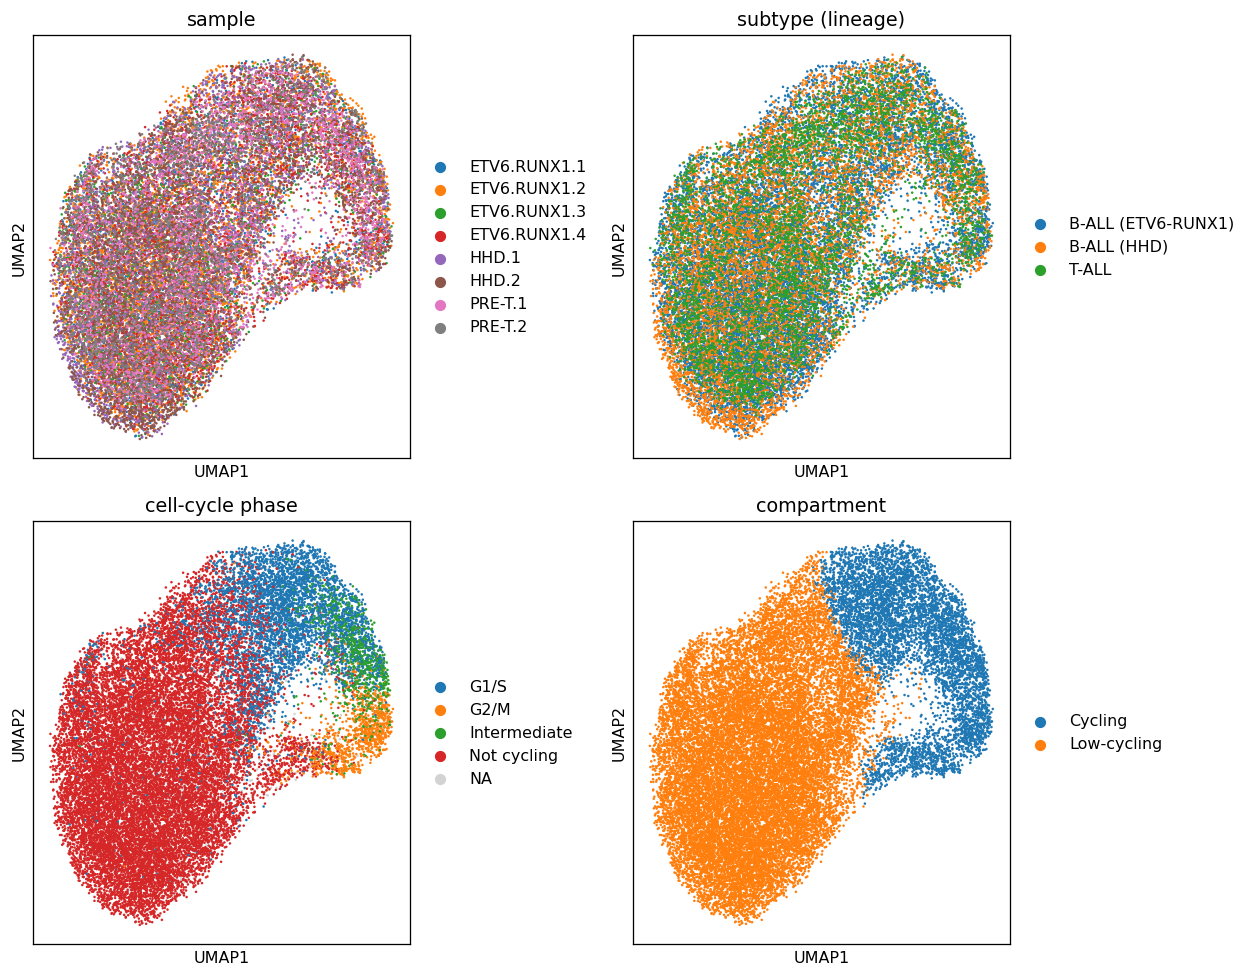

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8.6))
sc.pl.umap(adata, color='sample', size=10, ax=axes[0,0], show=False, title='sample')
sc.pl.umap(adata, color='subtype', size=10, ax=axes[0,1], show=False, title='subtype (lineage)')
sc.pl.umap(adata, color='cell_cycle_phase', size=10, ax=axes[1,0], show=False, title='cell-cycle phase')
sc.pl.umap(adata, color='compartment', size=10, ax=axes[1,1], show=False, title='compartment')
fig.tight_layout()
print(f'8 samples + 3 subtypes share one continuous manifold; sample-iLISI {sweep[theta]:.2f} of {ceil_s:.2f} ceiling.')
print('batch integration sound; the dominant visible split is the cell cycle (Cycling vs Low-cycling).')

### Scope out the cycling compartment (the sanctioned fix)
The whole-manifold trajectory is confounded by proliferation (established here; quantified in 02). We
therefore **scope the trajectory to the low-cycling embryonic compartment and completely remove the
cycling lobe** — not regress the signal out, but exclude it, exactly the Kildisiute2021 precedent
(keep the embryonic lobe, drop the cycling/metabolic compartment). Neighbours are recomputed on the
Harmony PC representation (independent of the UMAP, so no re-embedding of a linear compartment —
03_eval fork 4), then a UMAP radius-graph pass removes any detached remnants so no island survives.
Cell counts dropped are documented. **Gate 1 on the scoped embryonic manifold: samples remain
intermixed on one continuous connected component -> GO.**

In [9]:
n_whole = adata.shape[0]
adata = adata[adata.obs['compartment'] == 'Low-cycling'].copy()
n_scope = adata.shape[0]
print(f'scoped to embryonic (Low-cycling): kept {n_scope}, dropped {n_whole-n_scope} cycling-lobe cells')
# recompute neighbours on Harmony PCs (NOT a fresh UMAP) then strip detached remnants
sc.pp.neighbors(adata, n_pcs=NP, use_rep='X_pca_harmony', n_neighbors=NN, random_state=SEED)
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('detached remnants removed after scoping:', int((lab!=main).sum()), 'in', ncomp-1, 'components')
adata = adata[lab==main].copy()
sc.pp.neighbors(adata, n_pcs=NP, use_rep='X_pca_harmony', n_neighbors=NN, random_state=SEED)
nkc, _ = connected_components(adata.obsp['connectivities'], directed=False)
print(f'scoped embryonic manifold: {adata.shape[0]} cells | kNN components = {nkc} (1 = fully continuous)')
cyc_frac = adata.obs['cycling'].mean()
print(f'residual cycling fraction in scoped set: {cyc_frac:.3f} (boundary cells; resolved confound quantified in 02)')
print('Gate 1 (scoped): 8 samples intermixed on one continuous component -> GO')

scoped to embryonic (Low-cycling): kept 19815, dropped 5973 cycling-lobe cells
detached remnants removed after scoping: 15 in 9 components
scoped embryonic manifold: 19800 cells | kNN components = 1 (1 = fully continuous)
residual cycling fraction in scoped set: 0.059 (boundary cells; resolved confound quantified in 02)
Gate 1 (scoped): 8 samples intermixed on one continuous component -> GO


In [10]:
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad (scoped embryonic manifold)', adata.shape)

saved processed.h5ad (scoped embryonic manifold) (19800, 21935)


### Deliverable — `samples.pdf` (scoped embryonic manifold, sample-coloured)
House style `figsize=(3.5,1.5)`, `size=30`, colour = sample; intermixing across the scoped embryonic
manifold is the Gate-1 batch-integration evidence, matching the reference `samples.pdf` format.

saved samples.pdf | cells: 19800


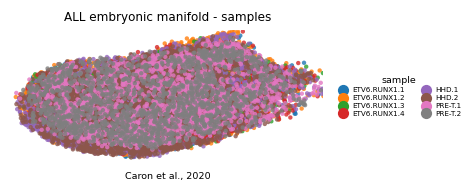

In [11]:
plot = adata.copy()
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5, 1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=2, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.25, fontsize=4.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('ALL embryonic manifold - samples', size=7.5)
ax.text(.5, -.12, 'Caron et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig, 'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])